<a href="https://colab.research.google.com/github/QuentinMourier/AAA_ml_project/blob/main/movies_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP Data Learning : modèle sur la base de films

Données : `movies_metadata.csv`, The Movies Dataset, 45 466 films, 24 colonnes, stocké dans le repo GitHub du projet.

## 1. Chargement et exploration des données

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
DATA_URL = "https://raw.githubusercontent.com/QuentinMourier/AAA_ml_project/main/datasets/movies_metadata.csv"
movies = pd.read_csv(DATA_URL, low_memory=False)
print(movies.shape)
movies.head()

(45466, 24)


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


In [8]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-null  object 
 15  re

In [9]:
# Pourcentage de valeurs manquantes par colonne
(movies.isna().mean() * 100).round(1).sort_values(ascending=False)

,0
belongs_to_collection,90.1
homepage,82.9
tagline,55.1
overview,2.1
poster_path,0.8
runtime,0.6
status,0.2
release_date,0.2
original_language,0.0
imdb_id,0.0


## 2. Nettoyage des types

`budget`, `popularity` et `id` sont lues comme du texte : 3 lignes sont décalées, avec un chemin d'image dans `budget` et une date dans `id`. On convertit ces colonnes en numérique et on supprime ces 3 lignes.

Attention : un `budget` ou un `revenue` à 0 signifie en pratique « non renseigné », ce qui concerne la majorité des films.

In [10]:
num_cols = ["budget", "popularity", "id"]
movies[num_cols] = movies[num_cols].apply(pd.to_numeric, errors="coerce")
movies = movies.dropna(subset=["id"]).astype({"id": int})
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
print(movies.shape)
movies[["budget", "revenue", "popularity", "runtime", "vote_average", "vote_count"]].describe()

(45463, 24)


,budget,revenue,popularity,runtime,vote_average,vote_count
count,4.546300e+04,4.546000e+04,45460.000000,45203.000000,45460.000000,45460.000000
mean,4.224579e+06,1.120935e+07,2.921478,94.128199,5.618207,109.897338
std,1.742413e+07,6.433225e+07,6.005414,38.407810,1.924216,491.310374
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,0.000000e+00,0.000000e+00,0.385948,85.000000,5.000000,3.000000
50%,0.000000e+00,0.000000e+00,1.127685,95.000000,6.000000,10.000000
75%,0.000000e+00,0.000000e+00,3.678902,107.000000,6.800000,34.000000
max,3.800000e+08,2.787965e+09,547.488298,1256.000000,10.000000,14075.000000


## 3. Variable cible : `revenue` (box office)

Un `revenue` à 0 signifie « non renseigné » : on ne garde que les films avec `revenue > 0`, soit 7 408 films. La distribution est très asymétrique, avec quelques blockbusters à plusieurs milliards : on travaillera sur `log(1 + revenue)`.

In [11]:
df = movies[movies["revenue"] > 0].copy()
df["log_revenue"] = np.log1p(df["revenue"])
print(df.shape)
df["revenue"].describe()

(7408, 25)


,revenue
count,7.408000e+03
mean,6.878739e+07
std,1.464203e+08
min,1.000000e+00
25%,2.400000e+06
50%,1.682272e+07
75%,6.722707e+07
max,2.787965e+09


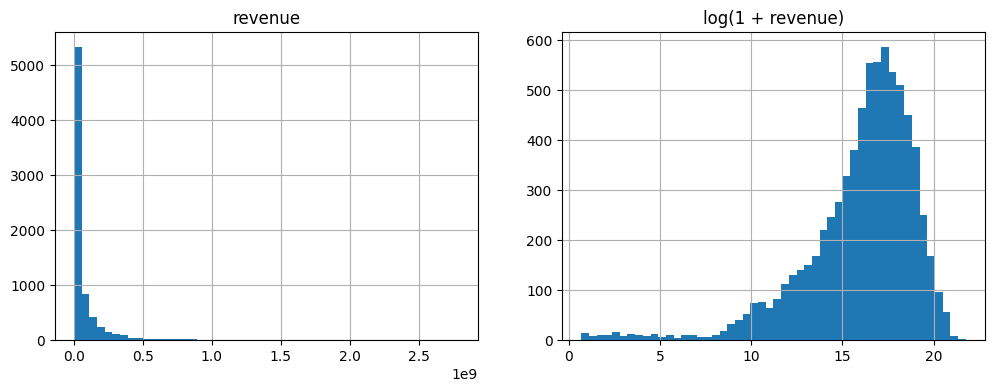

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["revenue"].hist(bins=50, ax=axes[0])
axes[0].set_title("revenue")
df["log_revenue"].hist(bins=50, ax=axes[1])
axes[1].set_title("log(1 + revenue)")
plt.show()

In [13]:
# Corrélation des variables numériques avec la cible
num_features = ["budget", "popularity", "runtime", "vote_average", "vote_count"]
df[num_features + ["log_revenue"]].corr()["log_revenue"].sort_values(ascending=False)

,log_revenue
log_revenue,1.000000
budget,0.491529
vote_count,0.427222
popularity,0.289735
runtime,0.222608
vote_average,0.175827
